# Common Substructures Across Activity Patterns

Same approach as the reference notebook, applied to all active compounds across all cell lines.

**Idea:**
- Each compound is labeled by which cell line(s) it activates
- Morgan fingerprints → t-SNE + UMAP → clusters colored by activity group
- BRICS fragments per cluster → what structure is shared inside each cluster?
- Within-cluster vs global Jaccard similarity → how tight is each cluster?

If compounds from **different activity groups** land in the same cluster → they share a common structure despite different selectivity.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from collections import Counter
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, BRICS, AllChem
from rdkit.Chem import rdFingerprintGenerator
from IPython.display import display
import itertools

BASE = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'

# Load activity table + SMILES
adf  = pd.read_csv(BASE + 'results/all_cell_line_comparisions/consistent_compounds_caspase_all.csv')
smi  = pd.read_csv(BASE + 'cleaned_datasets/combined_hepg2_casepase.csv',
                   usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
smi2 = pd.read_csv(BASE + 'cleaned_datasets/AID_1346980_cleaned.csv',
                   usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])

smiles_df = (pd.concat([smi, smi2])
               .dropna(subset=['PUBCHEM_EXT_DATASOURCE_SMILES'])
               .drop_duplicates('PUBCHEM_CID'))

df = adf.merge(smiles_df, on='PUBCHEM_CID', how='left')
df['Molecule'] = df['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None
)
df = df[df['Molecule'].notna()].reset_index(drop=True)

# Cell-line column → short name
CELL_LINES = {
    'AID_1346980': 'CHO-K1', 'AID_655': 'Jurkat', 'AID_656': 'HUV-EC-C',
    'AID_657': 'SHSY5Y', 'AID_658': 'BJ', 'AID_659': 'MRC-5',
    'AID_660': 'Mesangial', 'AID_661': 'SK-N-SH', 'AID_663': 'H-4-II-E',
    'AID_664': 'HEK293', 'AID_665': 'N2a', 'AID_666': 'NIH 3T3',
    'AID_667': 'Renal PT', 'combined_hepg2_casepase.csv': 'HepG2',
}

def activity_group(row):
    active = [name for col, name in CELL_LINES.items()
              if col in row.index and row[col] == 'Active']
    n = len(active)
    if n == 0:   return None
    if n == 1:   return f'Only {active[0]}'
    if n == 2:   return '+'.join(sorted(active))
    return f'{n} cell lines'

df['Activity Group'] = df.apply(activity_group, axis=1)

# Keep only active compounds
active_df = df[df['Activity Group'].notna()].reset_index(drop=True)

# Simplify small groups → "Other (multi-cell)"
counts = active_df['Activity Group'].value_counts()
keep   = counts[counts >= 5].index
active_df['Activity Group'] = active_df['Activity Group'].apply(
    lambda g: g if g in keep else 'Other active'
)

print(f"Active compounds: {len(active_df)}")
print()
print("Activity group sizes:")
print(active_df['Activity Group'].value_counts().to_string())

Active compounds: 323

Activity group sizes:
Activity Group
Only HepG2      142
CHO-K1+HepG2     67
Only CHO-K1      35
Other active     34
Only Jurkat      22
3 cell lines     13
4 cell lines      5
HEK293+HepG2      5


[19:50:54] WARNING: not removing hydrogen atom without neighbors


In [2]:
# Morgan fingerprints (ECFP4, 2048 bits)
def get_morgan_fp(mol):
    if mol is not None:
        return AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=2048)
    return None

active_df['Morgan_Fingerprint'] = active_df['Molecule'].apply(get_morgan_fp)

# Convert to numpy array
fp_size = 2048
fp_array = np.array([
    list(fp.ToBitString()) if fp is not None else [0]*fp_size
    for fp in active_df['Morgan_Fingerprint']
], dtype=np.uint8)

print(f"Fingerprint matrix shape: {fp_array.shape}")

Fingerprint matrix shape: (323, 2048)


[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerator
[19:50:54] DEPRECATION WARNING: please use MorganGenerat

## t-SNE — Chemical Space Colored by Activity Group

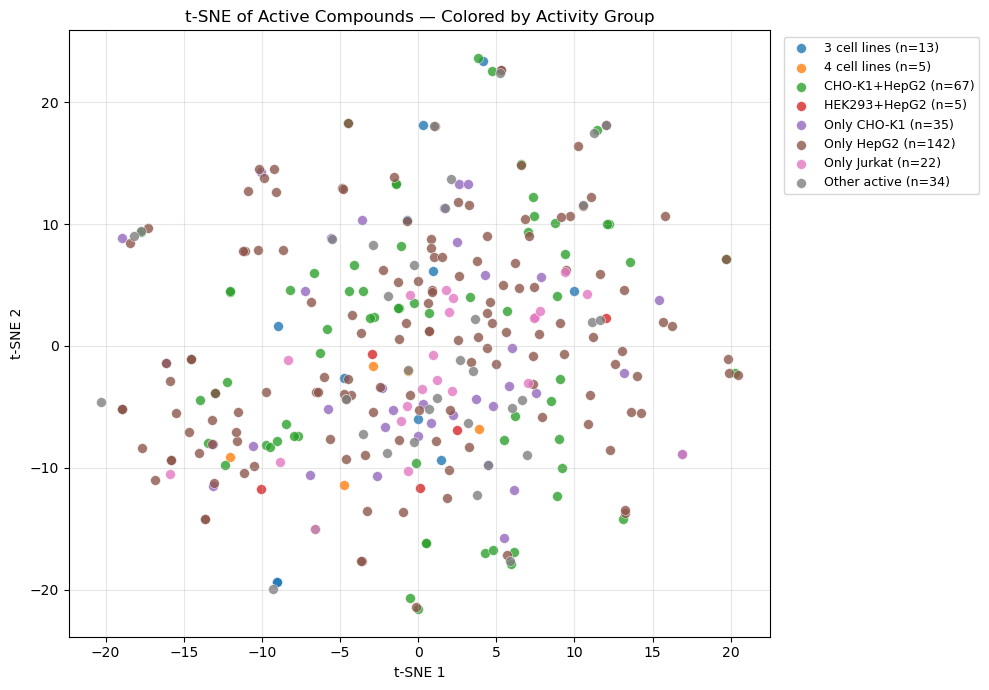

In [3]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, init='random', learning_rate='auto', perplexity=30)
tsne_coords = tsne.fit_transform(fp_array)

active_df['TSNE_1'] = tsne_coords[:, 0]
active_df['TSNE_2'] = tsne_coords[:, 1]

groups   = active_df['Activity Group'].unique()
palette  = sns.color_palette('tab10', len(groups))
color_map = dict(zip(sorted(groups), palette))

plt.figure(figsize=(10, 7))
for grp in sorted(groups):
    sub = active_df[active_df['Activity Group'] == grp]
    plt.scatter(sub['TSNE_1'], sub['TSNE_2'],
                label=f'{grp} (n={len(sub)})',
                color=color_map[grp], s=50, alpha=0.8, edgecolors='white', linewidths=0.4)

plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
plt.title('t-SNE of Active Compounds — Colored by Activity Group')
plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## UMAP — Same Data, Different Projection

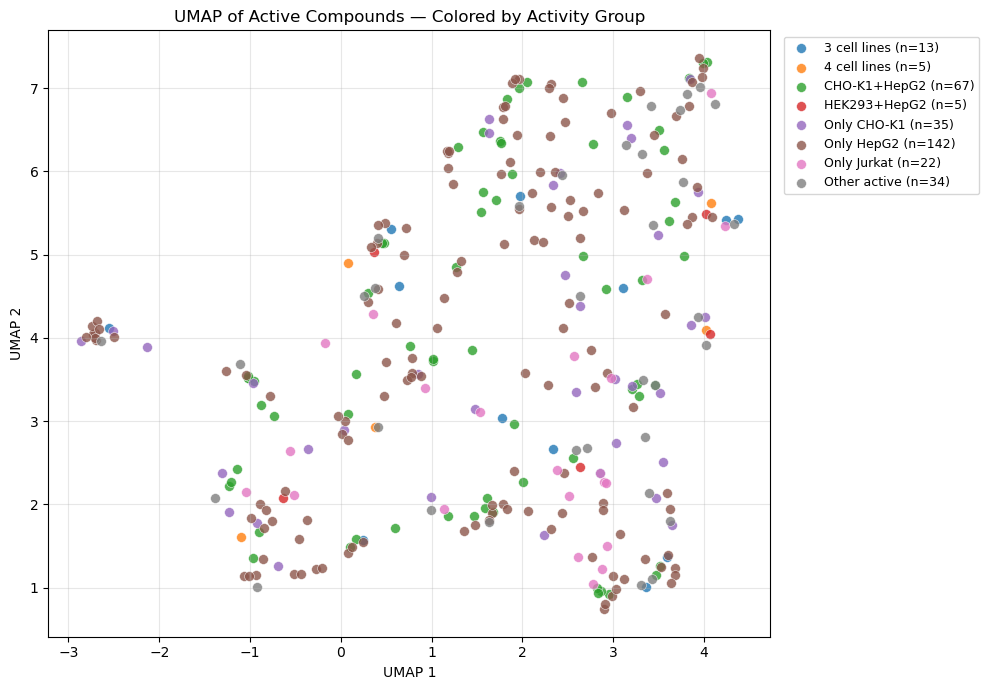

In [4]:
import umap

reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                    metric='jaccard', random_state=42)
umap_coords = reducer.fit_transform(fp_array)

active_df['UMAP_1'] = umap_coords[:, 0]
active_df['UMAP_2'] = umap_coords[:, 1]

plt.figure(figsize=(10, 7))
for grp in sorted(groups):
    sub = active_df[active_df['Activity Group'] == grp]
    plt.scatter(sub['UMAP_1'], sub['UMAP_2'],
                label=f'{grp} (n={len(sub)})',
                color=color_map[grp], s=50, alpha=0.8, edgecolors='white', linewidths=0.4)

plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
plt.title('UMAP of Active Compounds — Colored by Activity Group')
plt.xlabel('UMAP 1'); plt.ylabel('UMAP 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## KMeans Clustering — Find Structural Families

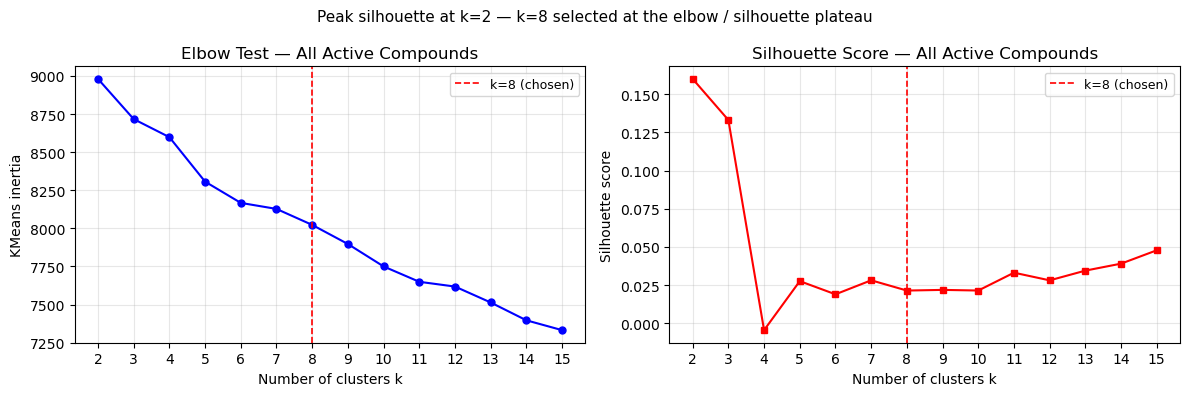

Silhouette scores: {2: 0.1601, 3: 0.1332, 4: -0.0046, 5: 0.0276, 6: 0.0189, 7: 0.0281, 8: 0.0214, 9: 0.0218, 10: 0.0214, 11: 0.0331, 12: 0.0281, 13: 0.0345, 14: 0.039, 15: 0.0478}
Peak silhouette at k=2 (score=0.1601)


In [5]:
# ── Elbow test: justify k=8 for KMeans on all active compounds ───────────────
# Sweep k=2..15, record inertia (elbow) and silhouette score (peak).
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_RANGE = range(2, 16)
inertias_all, silhouettes_all = [], []

for k in K_RANGE:
    km_tmp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km_tmp.fit_predict(fp_array)
    inertias_all.append(km_tmp.inertia_)
    silhouettes_all.append(silhouette_score(fp_array, labels, sample_size=1000, random_state=42))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(list(K_RANGE), inertias_all, 'bo-', linewidth=1.5, markersize=5)
ax1.axvline(8, color='red', linestyle='--', linewidth=1.2, label='k=8 (chosen)')
ax1.set_xlabel('Number of clusters k')
ax1.set_ylabel('KMeans inertia')
ax1.set_title('Elbow Test — All Active Compounds')
ax1.set_xticks(list(K_RANGE))
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

ax2.plot(list(K_RANGE), silhouettes_all, 'rs-', linewidth=1.5, markersize=5)
ax2.axvline(8, color='red', linestyle='--', linewidth=1.2, label='k=8 (chosen)')
ax2.set_xlabel('Number of clusters k')
ax2.set_ylabel('Silhouette score')
ax2.set_title('Silhouette Score — All Active Compounds')
ax2.set_xticks(list(K_RANGE))
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

best_k8 = list(K_RANGE)[silhouettes_all.index(max(silhouettes_all))]
plt.suptitle(f'Peak silhouette at k={best_k8} — k=8 selected at the elbow / silhouette plateau',
             fontsize=11)
plt.tight_layout()
plt.show()
print(f'Silhouette scores: {dict(zip(K_RANGE, [round(s,4) for s in silhouettes_all]))}')
print(f'Peak silhouette at k={best_k8} (score={max(silhouettes_all):.4f})')

Compounds per cluster:
Cluster
0      4
1    139
2      9
3     35
4      6
5     13
6     81
7     36
Name: count, dtype: int64


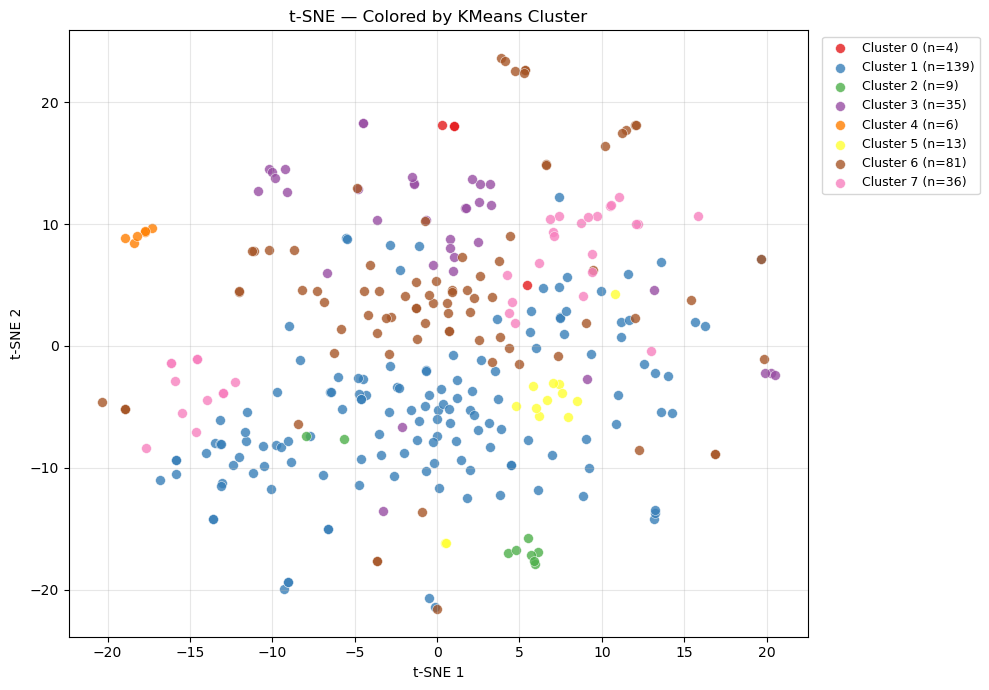

In [6]:
from sklearn.cluster import MiniBatchKMeans

n_clusters = 8
kmeans = MiniBatchKMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
active_df['Cluster'] = kmeans.fit_predict(fp_array)

print("Compounds per cluster:")
print(active_df['Cluster'].value_counts().sort_index())

# t-SNE colored by cluster
cluster_palette = sns.color_palette('Set1', n_clusters)

plt.figure(figsize=(10, 7))
for cl in range(n_clusters):
    sub = active_df[active_df['Cluster'] == cl]
    plt.scatter(sub['TSNE_1'], sub['TSNE_2'],
                label=f'Cluster {cl} (n={len(sub)})',
                color=cluster_palette[cl], s=50, alpha=0.8,
                edgecolors='white', linewidths=0.4)

plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
plt.title('t-SNE — Colored by KMeans Cluster')
plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Jaccard Similarity: Global vs Within-Cluster

How similar are molecules within each cluster vs the whole dataset?  
High within-cluster similarity → tight structural family → meaningful common substructure.

In [7]:
valid_fps = [fp for fp in active_df['Morgan_Fingerprint'] if fp is not None]

# Global average (sample 500 pairs max to keep it fast)
import random
random.seed(42)
pairs = list(itertools.combinations(range(len(valid_fps)), 2))
if len(pairs) > 2000:
    pairs = random.sample(pairs, 2000)

global_sims = [DataStructs.TanimotoSimilarity(valid_fps[i], valid_fps[j]) for i,j in pairs]
global_avg  = np.mean(global_sims)
print(f"Global Average Jaccard Similarity: {global_avg:.4f}")
print()

within_avg = {}
fps_list = active_df['Morgan_Fingerprint'].tolist()
for cl in range(n_clusters):
    cl_fps = [fps_list[i] for i in active_df[active_df['Cluster']==cl].index if fps_list[i] is not None]
    if len(cl_fps) < 2:
        within_avg[cl] = 0.0
        continue
    cl_pairs = list(itertools.combinations(range(len(cl_fps)), 2))
    if len(cl_pairs) > 500:
        cl_pairs = random.sample(cl_pairs, 500)
    sims = [DataStructs.TanimotoSimilarity(cl_fps[i], cl_fps[j]) for i,j in cl_pairs]
    within_avg[cl] = np.mean(sims)

print("Within-cluster Average Jaccard Similarity:")
for cl, avg in within_avg.items():
    n = (active_df['Cluster']==cl).sum()
    bar = '█' * int(avg * 30)
    print(f"  Cluster {cl} (n={n:3d}): {avg:.4f}  {bar}")

Global Average Jaccard Similarity: 0.0788

Within-cluster Average Jaccard Similarity:
  Cluster 0 (n=  4): 0.3801  ███████████
  Cluster 1 (n=139): 0.0633  █
  Cluster 2 (n=  9): 0.3973  ███████████
  Cluster 3 (n= 35): 0.1526  ████
  Cluster 4 (n=  6): 0.7223  █████████████████████
  Cluster 5 (n= 13): 0.2188  ██████
  Cluster 6 (n= 81): 0.1347  ████
  Cluster 7 (n= 36): 0.2098  ██████


## Cluster Composition — Which Activity Groups Are in Each Cluster?

This shows: do compounds from different activity groups end up in the same structural cluster?  
If yes → **same scaffold, different selectivity** — the most interesting finding.

Activity group breakdown per cluster:

Activity Group  3 cell lines  4 cell lines  CHO-K1+HepG2  HEK293+HepG2  Only CHO-K1  Only HepG2  Only Jurkat  Other active
Cluster                                                                                                                   
0                          1             0             0             0            0           2            0             1
1                          7             5            19             3           19          53           14            19
2                          0             0             5             0            1           2            0             1
3                          2             0             6             0            7          17            0             3
4                          0             0             1             0            1           2            0             2
5                          0             0             4             0            3           2     

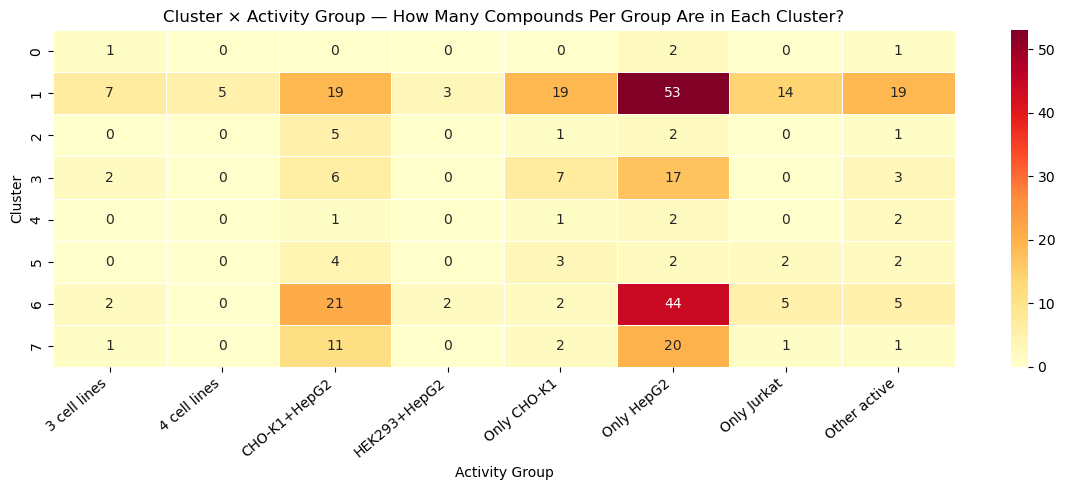

In [8]:
print("Activity group breakdown per cluster:\n")
composition = (active_df.groupby(['Cluster', 'Activity Group'])
               .size().unstack(fill_value=0))
print(composition.to_string())

# Heatmap
plt.figure(figsize=(12, 5))
sns.heatmap(composition, annot=True, fmt='d', cmap='YlOrRd', linewidths=0.5)
plt.title('Cluster × Activity Group — How Many Compounds Per Group Are in Each Cluster?')
plt.ylabel('Cluster'); plt.xlabel('Activity Group')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

## BRICS Fragments Per Cluster

For each cluster: what are the most common structural fragments?  
These are the shared substructures that define each cluster's chemical identity.

In [9]:
def get_brics_fragments(mol):
    if mol is None:
        return []
    frags = BRICS.BRICSDecompose(mol)
    result = []
    for block in frags:
        for smi in block.split('.'):
            m = Chem.MolFromSmiles(smi)
            if m:
                result.append(Chem.MolToSmiles(m, isomericSmiles=True))
    return list(set(result))

active_df['Fragments'] = active_df['Molecule'].apply(get_brics_fragments)
print("BRICS decomposition done.")

BRICS decomposition done.



Cluster 0  (n=4  Jaccard=0.380)
Activity groups: Only HepG2: 2  |  3 cell lines: 1  |  Other active: 1
Top 8 fragments:
                             SMILES  Count
                          [5*]N[5*]      4
[5*]N1C[C@H]2CCCC[C@H]2C[C@H]1[13*]      3
                      [16*]c1ccccc1      3
                       [4*]C(C)(C)C      3
                      [1*]C([6*])=O      3
    [4*]C[C@@H](O)[C@@H]([4*])C[4*]      2
                        [11*]S[11*]      2
                  [16*]c1cccc(O)c1C      2

Sample compounds:


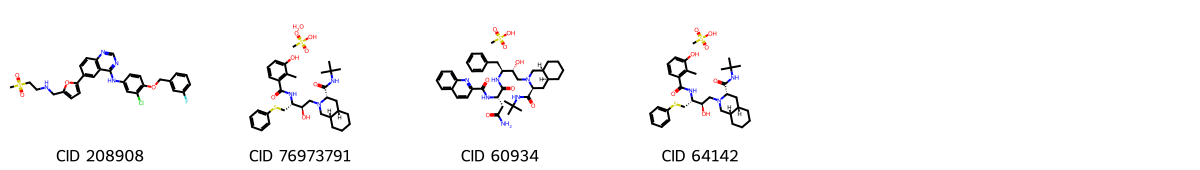

Top fragments:


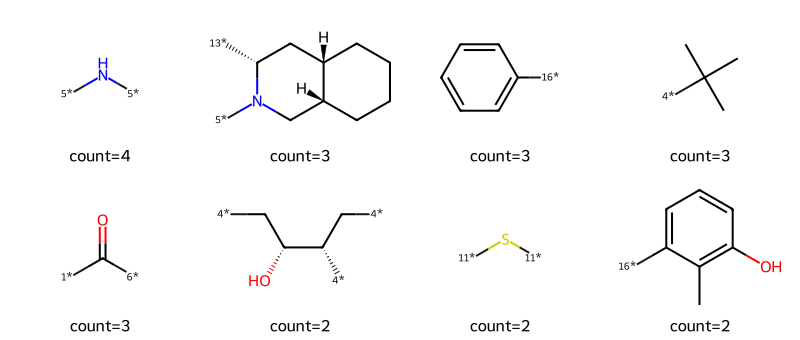


Cluster 1  (n=139  Jaccard=0.063)
Activity groups: Only HepG2: 53  |  CHO-K1+HepG2: 19  |  Only CHO-K1: 19  |  Other active: 19  |  Only Jurkat: 14  |  3 cell lines: 7  |  4 cell lines: 5  |  HEK293+HepG2: 3
Top 8 fragments:
              SMILES  Count
           [3*]O[3*]     18
              [3*]OC     17
           [5*]N[5*]     12
           [4*]C[8*]      8
             [4*]CCO      6
[16*]c1ccc([16*])cc1      6
       [1*]C([6*])=O      6
        [4*]CCCCCCCC      5

Sample compounds:


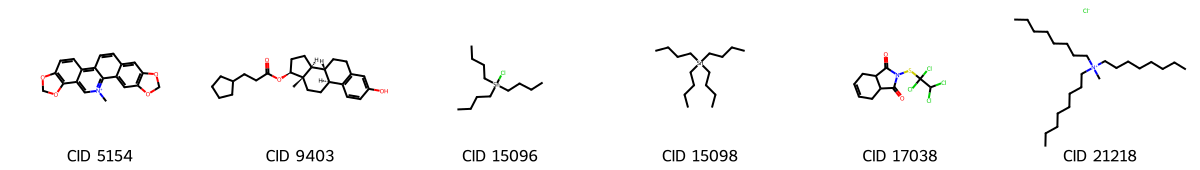

Top fragments:


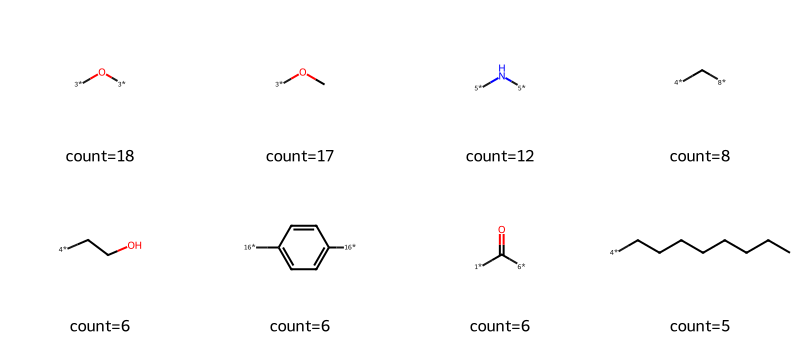


Cluster 2  (n=9  Jaccard=0.397)
Activity groups: CHO-K1+HepG2: 5  |  Only HepG2: 2  |  Only CHO-K1: 1  |  Other active: 1
Top 8 fragments:
                                 SMILES  Count
                           [1*]C(=O)C=C      8
                              [3*]O[3*]      8
              [4*]CC(C[4*])(C[4*])C[4*]      2
                 [4*]CC(C[4*])(C[4*])CO      2
                 [4*]CC(C[4*])(C[4*])CC      1
     [9*]n1c(=O)n([9*])c(=O)n([9*])c1=O      1
                             [4*]CC[8*]      1
[3*][O][Sn]([CH2]CCC)([CH2]CCC)[CH2]CCC      1

Sample compounds:


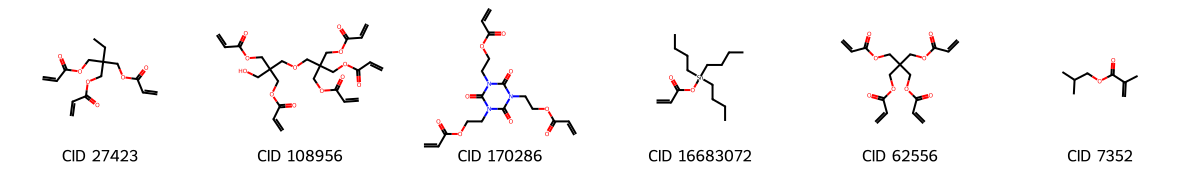

Top fragments:


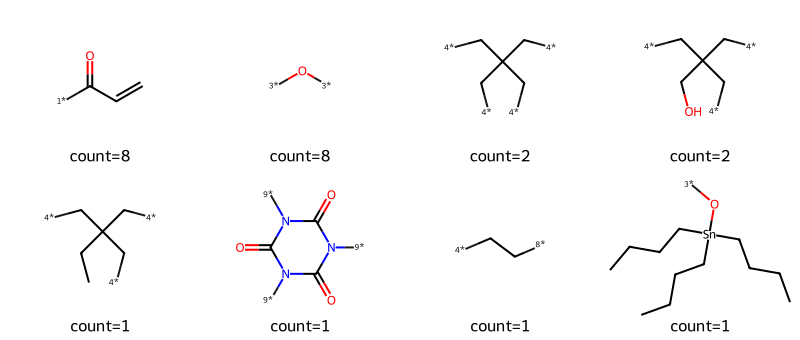


Cluster 3  (n=35  Jaccard=0.153)
Activity groups: Only HepG2: 17  |  Only CHO-K1: 7  |  CHO-K1+HepG2: 6  |  Other active: 3  |  3 cell lines: 2
Top 8 fragments:
          SMILES  Count
          [3*]OC     10
       [5*]N[5*]      8
   [1*]C([1*])=O      7
[16*]c1ccc(F)cc1      4
          [4*]CC      4
       [3*]O[3*]      4
   [1*]C([6*])=O      3
              Cl      3

Sample compounds:


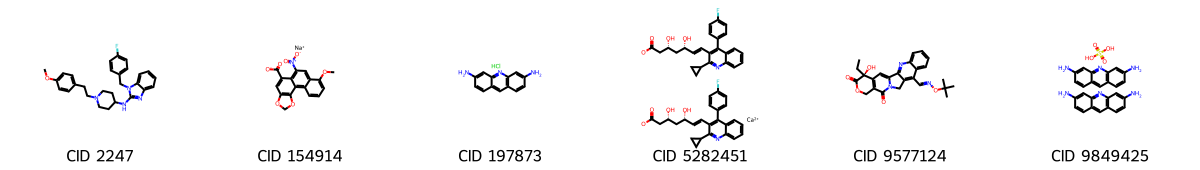

Top fragments:


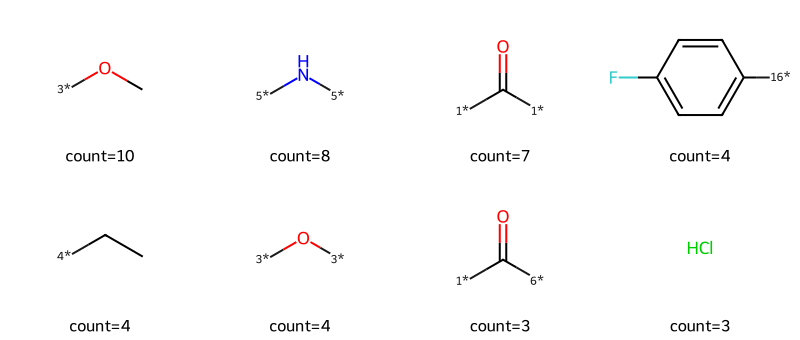


Cluster 4  (n=6  Jaccard=0.722)
Activity groups: Only HepG2: 2  |  Other active: 2  |  CHO-K1+HepG2: 1  |  Only CHO-K1: 1
Top 8 fragments:
                                                                SMILES  Count
                                                                [3*]OC      5
                                [13*][C@H]1C[C@H](N)[C@H](O)[C@H](C)O1      4
[3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)C(=O)c1c([16*])cccc1C3=O      4
                                                            [6*]C(C)=O      3
                                                           [6*]C(=O)CO      3
                                                    [13*][C@@H]1CCCCO1      1
                                                             [3*]O[3*]      1
                            [13*][C@H]1C[C@H](N)[C@H]([15*])[C@H](C)O1      1

Sample compounds:


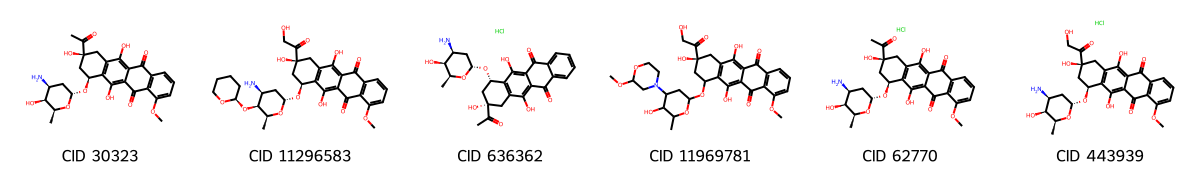

Top fragments:


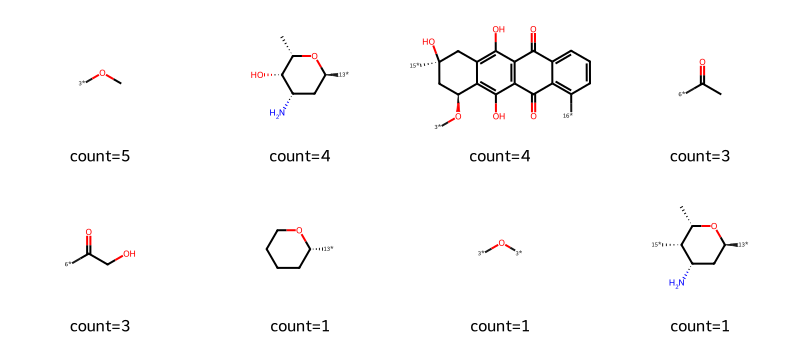


Cluster 5  (n=13  Jaccard=0.219)
Activity groups: CHO-K1+HepG2: 4  |  Only CHO-K1: 3  |  Only HepG2: 2  |  Only Jurkat: 2  |  Other active: 2
Top 8 fragments:
                                             SMILES  Count
                                          [3*]O[3*]      3
                                    [5*]N([5*])[5*]      2
                                       [8*]C(F)(F)F      2
                        [16*]c1ccc([N+](=O)[O-])cc1      2
                                            [4*]CCC      2
[16*]c1c([N+](=O)[O-])cc(S(N)(=O)=O)cc1[N+](=O)[O-]      1
                                         [6*]C(=O)O      1
                                  [16*]c1ccc(Cl)cc1      1

Sample compounds:


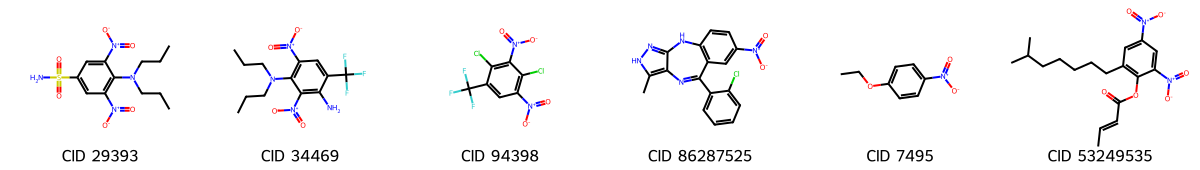

Top fragments:


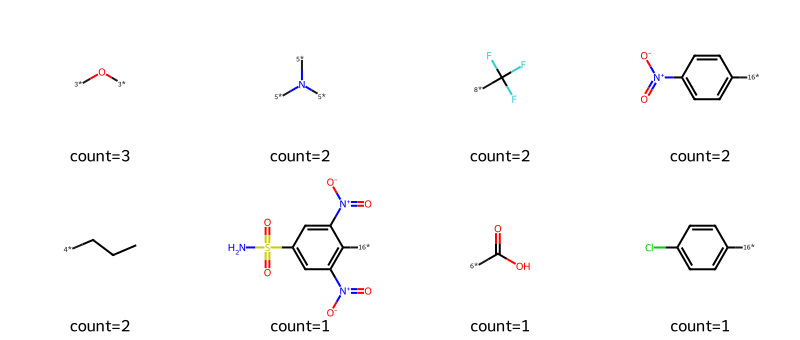


Cluster 6  (n=81  Jaccard=0.135)
Activity groups: Only HepG2: 44  |  CHO-K1+HepG2: 21  |  Only Jurkat: 5  |  Other active: 5  |  Only CHO-K1: 2  |  HEK293+HepG2: 2  |  3 cell lines: 2
Top 8 fragments:
              SMILES  Count
       [16*]c1ccccc1     31
[16*]c1ccc([16*])cc1     18
           [3*]O[3*]     17
           [5*]N(C)C     17
           [5*]N[5*]     13
          [4*]CC[4*]     12
       [1*]C([6*])=O     12
     [7*]C([8*])[8*]     10

Sample compounds:


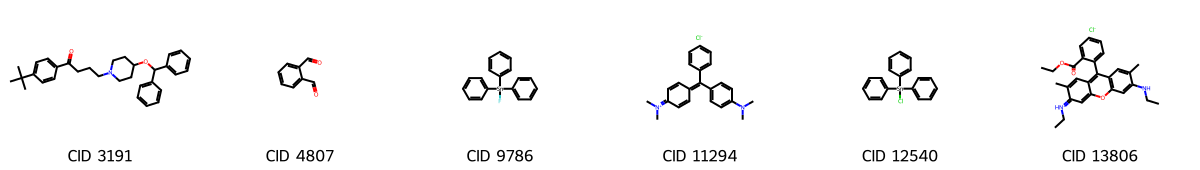

Top fragments:


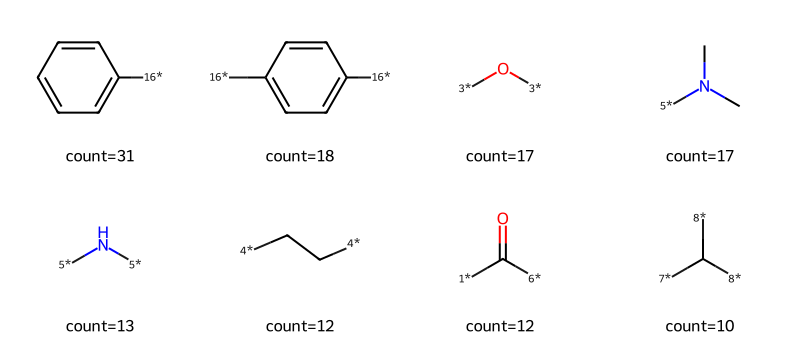


Cluster 7  (n=36  Jaccard=0.210)
Activity groups: Only HepG2: 20  |  CHO-K1+HepG2: 11  |  Only CHO-K1: 2  |  Only Jurkat: 1  |  Other active: 1  |  3 cell lines: 1
Top 8 fragments:
                 SMILES  Count
       [16*]c1ccc(O)cc1     11
              [3*]O[3*]     10
           [8*]C(C)(C)C      7
[16*]c1ccc(O)c([16*])c1      5
          [1*]C([6*])=O      5
              [8*]C[8*]      4
   [8*]C(C)(C)CC(C)(C)C      3
   [16*]c1ccc([16*])cc1      3

Sample compounds:


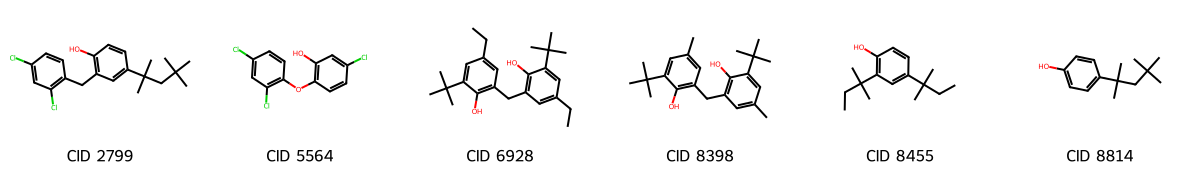

Top fragments:


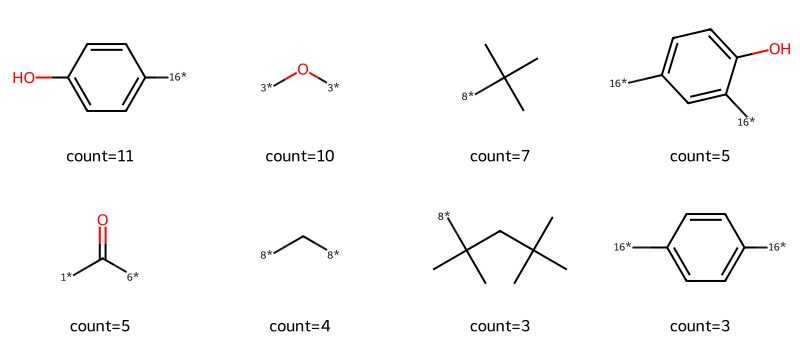

In [10]:
top_n = 8

for cl in range(n_clusters):
    cl_df  = active_df[active_df['Cluster'] == cl]
    n_cpds = len(cl_df)
    avg_j  = within_avg.get(cl, 0)

    # Activity group composition for this cluster
    grp_counts = cl_df['Activity Group'].value_counts().to_dict()
    grp_str    = '  |  '.join(f'{g}: {c}' for g, c in grp_counts.items())

    print(f"\n{'='*60}")
    print(f"Cluster {cl}  (n={n_cpds}  Jaccard={avg_j:.3f})")
    print(f"Activity groups: {grp_str}")

    # Top BRICS fragments
    all_frags = [f for frags in cl_df['Fragments'] for f in frags]
    frag_df   = (pd.DataFrame(Counter(all_frags).items(), columns=['SMILES', 'Count'])
                 .sort_values('Count', ascending=False).reset_index(drop=True))
    print(f"Top {top_n} fragments:")
    print(frag_df.head(top_n)[['SMILES','Count']].to_string(index=False))

    # Draw top fragments
    frag_mols, frag_legs = [], []
    for _, row in frag_df.head(top_n).iterrows():
        m = Chem.MolFromSmiles(row['SMILES'])
        if m:
            frag_mols.append(m)
            frag_legs.append(f"count={row['Count']}")

    # Draw sample compounds from this cluster
    sample_mols = cl_df['Molecule'].head(6).tolist()
    sample_legs = [f"CID {int(c)}" for c in cl_df['PUBCHEM_CID'].head(6)]

    if sample_mols:
        print("\nSample compounds:")
        img1 = Draw.MolsToGridImage(sample_mols, molsPerRow=6,
                                     subImgSize=(200,170), legends=sample_legs, returnPNG=False)
        display(img1)

    if frag_mols:
        print("Top fragments:")
        img2 = Draw.MolsToGridImage(frag_mols, molsPerRow=min(4, len(frag_mols)),
                                     subImgSize=(200,170), legends=frag_legs, returnPNG=False)
        display(img2)

## Summary

In [11]:
print("=== SUMMARY ===")
print(f"Active compounds analysed : {len(active_df)}")
print(f"KMeans clusters           : {n_clusters}")
print(f"Global Jaccard similarity : {global_avg:.4f}")
print()
print("Cluster summary (sorted by within-cluster Jaccard — tightest first):")
print(f"{'Cluster':>8} {'n':>5} {'Jaccard':>8}  Activity groups")
for cl, avg in sorted(within_avg.items(), key=lambda x: -x[1]):
    n    = (active_df['Cluster']==cl).sum()
    grps = active_df[active_df['Cluster']==cl]['Activity Group'].value_counts().to_dict()
    top  = ', '.join(f'{k}({v})' for k,v in list(grps.items())[:3])
    print(f"  {cl:>6} {n:>5} {avg:>8.4f}  {top}")

=== SUMMARY ===
Active compounds analysed : 323
KMeans clusters           : 8
Global Jaccard similarity : 0.0788

Cluster summary (sorted by within-cluster Jaccard — tightest first):
 Cluster     n  Jaccard  Activity groups
       4     6   0.7223  Only HepG2(2), Other active(2), CHO-K1+HepG2(1)
       2     9   0.3973  CHO-K1+HepG2(5), Only HepG2(2), Only CHO-K1(1)
       0     4   0.3801  Only HepG2(2), 3 cell lines(1), Other active(1)
       5    13   0.2188  CHO-K1+HepG2(4), Only CHO-K1(3), Only HepG2(2)
       7    36   0.2098  Only HepG2(20), CHO-K1+HepG2(11), Only CHO-K1(2)
       3    35   0.1526  Only HepG2(17), Only CHO-K1(7), CHO-K1+HepG2(6)
       6    81   0.1347  Only HepG2(44), CHO-K1+HepG2(21), Only Jurkat(5)
       1   139   0.0633  Only HepG2(53), CHO-K1+HepG2(19), Only CHO-K1(19)
